# 06 · What the strategies pick, and where they win or lose

Notebooks 03–05 showed **that** the headline model loses to a plain 6-month momentum rule. This one
asks **why**. It compares the two strategies, both buying the top 10 and holding one month:
- **the headline model** (XGBoost, trained on how much a stock beats SPY by);
- **the 6-month rule** (the 10 members that rose most over the past 6 months).

**Everything here is descriptive.** Slicing results many ways always finds some slice that looks
good by chance, so nothing found here is turned into a strategy or tested on these years.
Improvement ideas are written as hypotheses at the end.

**Margins of error are computed across months, not picks.** Ten picks made in the same month move
together, so each slice is averaged within each month first, then over months. A 95% margin is about
±2 standard errors.

Periods by decision date: **2020–2022** and the **test years** (decisions from January 2023).

> Numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.

In [1]:
import pandas as pd

from sp500_momentum import backtest as bt
from sp500_momentum import config, nb, plots
from sp500_momentum import diagnostics as dg

nb.setup()  # caps table output, silences info logs, applies the chart style (see sp500_momentum/nb.py)

In [2]:
panel = pd.read_parquet(config.MONTHLY_PANEL)
features = pd.read_parquet(config.FEATURES_TABLE, columns=dg.FEATURE_COLUMNS)
prices = pd.read_parquet(config.MONTHLY_PRICES)
scores = pd.read_parquet(config.MODEL_SCORES)
comparison = pd.read_csv(config.REPORTS_DIR / "model_comparison.csv")
headline = comparison.loc[comparison["headline"], "model"].iloc[0]

picks = {
    "model": bt.buffered_picks(
        bt.ranked(bt.merge_scores(panel, scores, [headline]), headline), 10, keep=10
    ),
    "rule": bt.buffered_picks(bt.ranked(panel, "ret_6m"), 10, keep=10),
}
names = {"model": "Headline model, top 10", "rule": "Rule: 6-month top 10"}
periods = {
    "2020–2022": (config.SPLIT["validation"][0], config.RULE_CHECK_FROM),
    "test years": (config.RULE_CHECK_FROM, None),
}
# VIX "high" means above its median over the development decisions (2010-2022), fixed in advance
monthly_vix = features.groupby("date")["vix"].first()
vix_cut = monthly_vix[monthly_vix.index < config.RULE_CHECK_FROM].median()

rows = dg.universe(panel, features, periods)
for s, p in picks.items():
    rows = dg.mark_picks(rows, p, s)
rows = dg.regimes(rows, bt.trend_signal(prices), vix_cut)
print(
    f"{len(rows):,} member-months; picks: "
    + ", ".join(f"{names[s]} {int(rows[s].sum())}" for s in picks)
    + f"; VIX cut: {vix_cut:.1f}"
)

40,000 member-months; picks: Headline model, top 10 810, Rule: 6-month top 10 810; VIX cut: 17.1


## 1. What the picks look like

Each pick's percentile among that month's members, averaged (50 = the average member). This shows
what kind of stock each strategy actually buys.

In [3]:
exp = dg.exposures(rows, list(picks))
exp.rename(index=names, level="strategy")

,,Volatility (12 months),Beta to SPY (36 months),Size (dollar volume),6-month return,Last month's return
period,strategy,,,,,
2020–2022,"Headline model, top 10",83.0825,77.2043,55.4715,23.6050,19.7431
test years,"Headline model, top 10",89.7313,66.6090,53.6352,20.2797,32.6703
2020–2022,Rule: 6-month top 10,78.9583,70.0225,70.0545,99.0697,74.1957
test years,Rule: 6-month top 10,85.5375,74.9310,78.9635,99.1006,74.7330


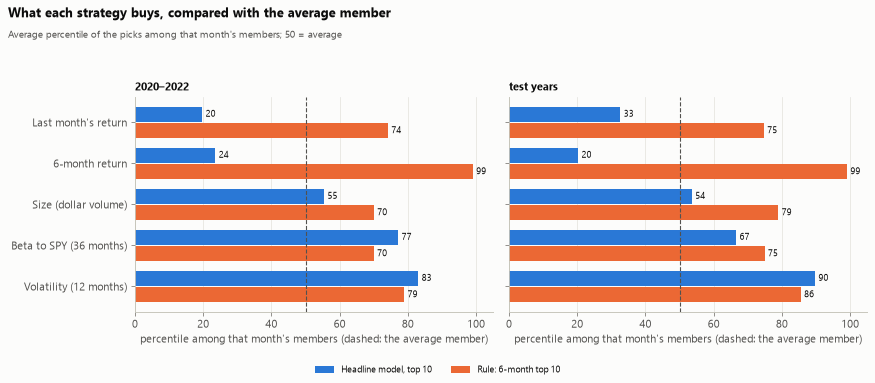

In [4]:
fig = plots.exposure_chart(
    exp,
    names,
    "What each strategy buys, compared with the average member",
    "Average percentile of the picks among that month's members; 50 = average",
)
plots.save(fig, "diag_exposures")

## 2. Does it only work in some markets?

The share of picks that beat SPY, minus the share of all members that did, in the same months. Three
ways of cutting the months: SPY above or below its 10-month average at the decision (known in
advance), VIX above or below its 2010–2022 median (known in advance), and whether SPY rose the next
month (known only afterwards: a description, not a signal).

In [5]:
regime = {
    s: pd.concat([dg.slice_table(rows, s, by) for by in ["trend", "vix_level", "market"]])
    for s in picks
}
cols = ["months", "hit_rate", "hit_se", "base_rate", "lift", "excess", "excess_se"]
pd.concat({names[s]: t[cols] for s, t in regime.items()})

months  hit_rate  hit_se  base_rate    lift  excess  excess_se
                       period                                                                                        
Headline model, top 10 2020–2022  SPY above its trend      24    0.4708  0.0603     0.4945 -0.0237  0.0093     0.0225
                                  SPY below its trend      12    0.5333  0.0940     0.5088  0.0246  0.0175     0.0494
                       test years SPY above its trend      41    0.4463  0.0313     0.4592 -0.0129 -0.0108     0.0101
                                  SPY below its trend       4    0.5000  0.1080     0.3743  0.1257  0.0178     0.0209
                       2020–2022  VIX high                 32    0.5219  0.0517     0.5114  0.0105  0.0184     0.0242
...                                                       ...       ...     ...        ...     ...     ...        ...
Rule: 6-month top 10   test years VIX low                  29    0.5034  0.0456     0.4465  0.0569  0.0093     0.0196
                       2020–2022  SPY down next month      13    0.5308  0.0804     0.5263  0.0044  0.0069     0.0172
                                  SPY up next month        23    0.5304  0.0520     0.4840  0.0464  0.0076     0.0133
                       test years SPY down next month      13    0.4462  0.0550     0.5108 -0.0646 -0.0178     0.0162
                                  SPY up next month        32    0.5625  0.0403     0.4277  0.1348  0.0279     0.0174

[24 rows x 7 columns]

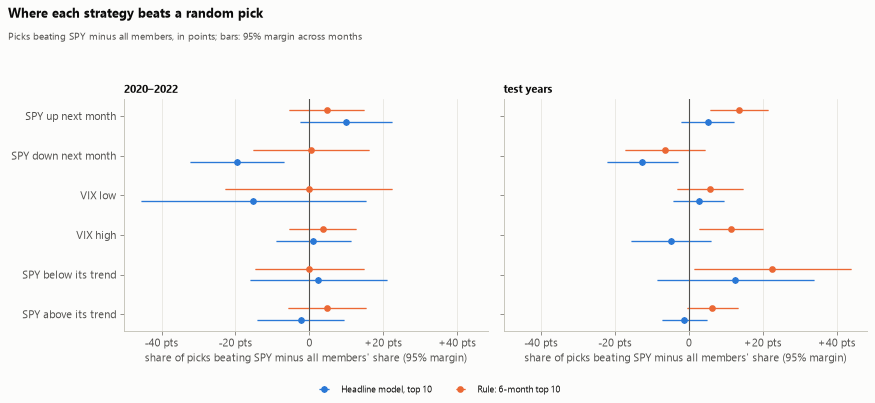

In [6]:
fig = plots.lift_chart(
    regime,
    names,
    "Where each strategy beats a random pick",
    "Picks beating SPY minus all members, in points; bars: 95% margin across months",
)
plots.save(fig, "diag_regimes")

## 3. By sector

How the picks are spread over sectors compared with the members, and how the picks did in each
sector (only sectors with picks in at least 6 months are shown; smaller slices are mostly noise).

In [7]:
mix = dg.sector_mix(rows, list(picks)).rename(columns=names)
mix["model minus members"] = mix[names["model"]] - mix["members"]
mix.sort_values(["period", names["model"]], ascending=[True, False]).groupby("period").head(5)

members  Headline model, top 10  Rule: 6-month top 10  model minus members
period     sector                                                                                            
2020–2022  Financials               0.1474                  0.2111                0.0500               0.0637
           Energy                   0.0458                  0.2083                0.2444               0.1625
           Consumer Discretionary   0.1145                  0.1833                0.1528               0.0688
           Communication Services   0.0488                  0.1056                0.0222               0.0568
           Industrials              0.1514                  0.0972                0.0528              -0.0542
test years Information Technology   0.1361                  0.2711                0.4622               0.1351
           Health Care              0.1235                  0.1867                0.0489               0.0632
           Consumer Discretionary   0.1013                  0.1378                0.1156               0.0365
           Financials               0.1455                  0.1156                0.0311              -0.0299
           Communication Services   0.0453                  0.1022                0.0600               0.0569

In [8]:
sector = pd.concat({names[s]: dg.slice_table(rows, s, "sector") for s in picks})
sector = sector[sector["months"] >= 6]
sector[cols].sort_values(["lift"], ascending=False).groupby(level=[0, 1]).head(4)

months  hit_rate  hit_se  base_rate    lift  excess  excess_se
                       period     sector                                                                                
Rule: 6-month top 10   test years Communication Services      18    0.6574  0.1004     0.4471  0.2104  0.0100     0.0171
                                  Materials                   13    0.6154  0.1404     0.4086  0.2068  0.0070     0.0308
                                  Information Technology      45    0.6424  0.0487     0.4890  0.1534  0.0508     0.0217
                       2020–2022  Materials                   27    0.6358  0.0907     0.5037  0.1321  0.0368     0.0215
                                  Financials                  16    0.6250  0.1250     0.5002  0.1248  0.0077     0.0146
Headline model, top 10 test years Consumer Staples            16    0.5208  0.1074     0.4050  0.1159  0.0058     0.0188
Rule: 6-month top 10   test years Industrials                 27    0.5617  0.0821     0.4492  0.1125 -0.0004     0.0132
                       2020–2022  Energy                      22    0.6121  0.0926     0.5441  0.0680  0.0277     0.0215
Headline model, top 10 test years Industrials                 22    0.5000  0.1091     0.4538  0.0462  0.0029     0.0248
Rule: 6-month top 10   2020–2022  Health Care                 25    0.5133  0.0888     0.4840  0.0293 -0.0037     0.0139
Headline model, top 10 2020–2022  Energy                      16    0.5125  0.1075     0.4858  0.0267  0.0517     0.0733
                       test years Health Care                 38    0.4715  0.0654     0.4459  0.0256 -0.0005     0.0182
                       2020–2022  Consumer Discretionary      26    0.5385  0.0921     0.5138  0.0246  0.0299     0.0324
                       test years Real Estate                  9    0.3333  0.1667     0.3119  0.0214 -0.0633     0.0358
                       2020–2022  Communication Services      13    0.4872  0.1071     0.4689  0.0183  0.0051     0.0343
                                  Financials                  24    0.4991  0.0865     0.5315 -0.0325  0.0054     0.0186

## 4. By year

One row per decision year, so a good total can be traced to one year or several.

In [9]:
rows["year"] = rows["month"].dt.year
pd.concat({names[s]: dg.slice_table(rows, s, "year") for s in picks})[cols]

months  hit_rate  hit_se  base_rate    lift  excess  excess_se
                       period     year                                                                
Headline model, top 10 2020–2022  2020      12    0.4833  0.0999     0.4653  0.0180  0.0293     0.0584
                                  2021      12    0.4750  0.0836     0.4885 -0.0135  0.0041     0.0195
                                  2022      12    0.5167  0.0851     0.5440 -0.0273  0.0027     0.0268
                       test years 2023      12    0.4667  0.0801     0.4310  0.0356  0.0021     0.0273
                                  2024      12    0.4250  0.0494     0.4530 -0.0280 -0.0199     0.0115
                                  2025      12    0.5000  0.0369     0.4587  0.0413  0.0008     0.0114
                                  2026       9    0.4000  0.0687     0.4680 -0.0680 -0.0185     0.0226
Rule: 6-month top 10   2020–2022  2020      12    0.5500  0.0452     0.4653  0.0847  0.0115     0.0088
                                  2021      12    0.4583  0.0900     0.4885 -0.0302 -0.0125     0.0213
                                  2022      12    0.5833  0.0842     0.5440  0.0394  0.0231     0.0208
                       test years 2023      12    0.5083  0.0529     0.4310  0.0773  0.0000     0.0104
                                  2024      12    0.5250  0.0664     0.4530  0.0720 -0.0008     0.0177
                                  2025      12    0.5333  0.0569     0.4587  0.0746  0.0343     0.0269
                                  2026       9    0.5556  0.1069     0.4680  0.0875  0.0287     0.0521

## 5. The worst picks

Each strategy's eight worst pick-months per period (next month's return minus SPY's): what they
were, what they had done before, and whether they were delisted the next month or left the index
within a year.

In [10]:
worst = pd.concat({names[s]: dg.worst_picks(rows, s) for s in picks})
worst

period       date ticker                  sector  fwd_excess_1m  ret_6m  vol_12m_pct  delisted_next_month  left_within_12m
Headline model, top 10 0    2020–2022 2020-02-28   NCLH  Consumer Discretionary        -0.5534 -0.2658      82.6552                False            False
                       1    2020–2022 2022-01-31   EPAM  Information Technology        -0.5231 -0.1494      95.2869                False            False
                       2    2020–2022 2020-02-28    MRO                  Energy        -0.4391 -0.2942      94.4325                False            False
                       3    2020–2022 2020-02-28   FANG                  Energy        -0.4350 -0.3663      89.0792                False            False
                       4    2020–2022 2020-02-28    DVN                  Energy        -0.4347 -0.2560      98.5011                False            False
...                               ...        ...    ...                     ...            ...     ...          ...                  ...              ...
Rule: 6-month top 10   11  test years 2024-06-28   CRWD  Information Technology        -0.4106  0.5008      87.3494                False            False
                       12  test years 2026-06-30   MRVL  Information Technology        -0.3667  2.5097      98.2000                False            False
                       13  test years 2026-06-30   INTC  Information Technology        -0.3511  2.7840      99.8000                False            False
                       14  test years 2026-09-30   SNDK  Information Technology        -0.3263  1.7385     100.0000                False            False
                       15  test years 2025-07-31   SMCI  Information Technology        -0.3170  1.0677      99.8012                False            False

[32 rows x 9 columns]

In [11]:
for s in picks:
    p = rows[rows[s] == 1]
    print(
        f"{names[s]}: picks delisted the next month: {int(p['delisted_next_month'].sum())}; "
        f"left the index within 12 months: {p['left_within_12m'].mean():.0%} "
        f"(all members: {rows['left_within_12m'].mean():.0%})"
    )

Headline model, top 10: picks delisted the next month: 0; left the index within 12 months: 16% (all members: 2%)
Rule: 6-month top 10: picks delisted the next month: 0; left the index within 12 months: 0% (all members: 2%)


## 6. What this means, and ideas to test in future

**What was found**

- **The headline model isn't a momentum strategy: it buys volatile, beaten-down stocks.**
  - Its picks sit around the 83rd–90th percentile for volatility, with an above-average beta. But they
    rank only around the 20th–24th percentile on 6-month return, and the 20th–33rd on last month's.
    In effect it's a bet on rebounds.
  - The 6-month rule is also volatile (79th–86th percentile), but its picks are the period's
    winners (99th percentile on 6-month return) and larger companies (70th–79th percentile on size,
    against about the 55th for the model).
- **The model's results follow the market's direction, and lose more than they gain.**
  - In months when SPY fell, its picks beat SPY only 33% of the time on 2020–2022 and 39% in the
    test years, against 53% and 51% for all members. That's 20 and 13 points worse, about 3 and 2.6
    standard errors: the only slices of the model clearly beyond noise.
  - In SPY's up months they did 10 and 5 points better than all members, which is not clearly beyond
    noise.
  - That's how a high-volatility, beaten-down portfolio behaves, and the down months cost more than
    the up months earn.
- **The 6-month rule is also a market-direction bet, but a winning one in the test years.**
  - In SPY's up months its picks beat the base rate by 13.5 points (3.3 standard errors); in down
    months they trailed it by 6.5.
  - 46% of its test-year picks were technology stocks, against 14% of members: the AI and memory-chip
    theme again.
- **Years:** the rule's picks beat the base rate in 6 of the 7 years; the model's in 3 (2020, 2023,
  2025). The rule's edge in hit rate is spread out, even though its dollar gain came in a burst.
- **Sectors:** the model leaned towards energy (21% of its picks against 5% of members) and
  financials on 2020–2022, and towards technology and health care in the test years. No sector slice
  of the model is clearly beyond noise.
- **The worst picks show each strategy's typical mistake.**
  - The model's worst came at the end of February 2020, when it bought beaten-down cruise and energy
    stocks (Norwegian Cruise Line, Marathon Oil, Diamondback, Devon) just before the Covid crash.
  - The rule's worst came in 2026, after enormous run-ups (SanDisk had risen over 800% in six
    months). SanDisk, Intel, Marvell and Super Micro then each did 30% or more worse than SPY in a
    single month.
- **16% of the model's picks left the index within a year,** against 2% of all members and under 1%
  of the rule's. Beaten-down stocks are often on their way out. None of either strategy's picks was
  delisted the following month.

**Hypotheses for future work (not built or tested here)**

There's no untouched data left in this project to test them on honestly. Each would need either new
months (the monthly run that starts after this project) or an earlier, separate period.

1. **Take the market's direction out of the model.** Its biggest losses are a bet on SPY rising. Ranking
   on returns after removing each stock's market exposure (beta-adjusted, or residual returns), or
   choosing within volatility bands, would test whether any stock-picking skill is left once that bet
   is removed.
2. **Give the model a risk-adjusted target.** Trained on the size of the win, it learned that volatile
   stocks win by most when they win. A target such as excess return divided by volatility, or the rank
   within the month, would stop the largest swings from dominating its top picks.
3. **Use the model as a filter for the rule, not a replacement.** The rule has the signal (past
   winners), and the model may have learned what precedes a collapse. Removing the rule's candidates
   that the model scores worst would test that without discarding the rule.
4. **Cap the rule's sector weights.** In the test years almost half its picks were technology stocks,
   so its result depends on one theme. A cap (for example, at most three stocks per sector) would make
   it less a bet on a theme and more on momentum itself.

All numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.
